# Credit Risk & Fraud Detection — Python Analysis

This notebook performs data inspection, quality validation, repayment analysis and exploratory analysis across five synthetic banking datasets (1.25 million rows in total).

## Run this notebook
1. Clone or download the repository.
2. Install the packages listed in `requirements.txt` (or install `pandas`, `numpy`, `matplotlib` and `seaborn`).
3. Open this notebook from either the repository root or the `Python/` folder.
4. Keep the five compressed CSV files in `datasets/cleaned/`; the notebook reads `.csv.gz` files directly.
5. Run the cells from top to bottom. Analysis exports are written to `outputs/python_analysis/`, leaving the source datasets unchanged.

**Data note:** The notebook starts from the committed cleaned datasets. It validates and analyzes them; it does not claim to repeat the original raw-data cleaning process. All records and labels are synthetic.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

# Locate the repository root whether this notebook is run from the project
# root or from inside the Python folder.
project_root_candidates = [Path.cwd(), Path.cwd().parent]
project_root = next(
    (
        path.resolve()
        for path in project_root_candidates
        if (path / "datasets" / "cleaned").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root. Open this notebook from the "
        "repository root or the Python folder."
    )

cleaned_dir = project_root / "datasets" / "cleaned"

datasets = {
    "customers": "customers_cleaned.csv.gz",
    "applications": "applications_cleaned.csv.gz",
    "loans": "loans_cleaned.csv.gz",
    "transactions": "transactions_cleaned.csv.gz",
    "repayments": "repayments_cleaned.csv.gz"
}

data = {}
for name, filename in datasets.items():
    file_path = cleaned_dir / filename
    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing {file_path}. Make sure the five files in "
            "datasets/cleaned/ are present in your local repository."
        )
    data[name] = pd.read_csv(file_path, compression="gzip")

print("All five committed cleaned datasets loaded successfully.")
print("Project root:", project_root)
for name, df in data.items():
    print(f"{name}: {len(df):,} rows × {len(df.columns)} columns")

All datasets loaded successfully!


In [ ]:
for name, df in data.items():
    print(f"{name}: {df.shape}")

customers: (87719, 9)
applications: (131579, 11)
loans: (65789, 12)
transactions: (438601, 13)
repayments: (526312, 9)


In [ ]:
for name, df in data.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")
    df.info()


DATASET: CUSTOMERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87719 entries, 0 to 87718
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   customer_id                87719 non-null  object
 1   age                        87719 non-null  int64 
 2   city                       87719 non-null  object
 3   employment_type            87719 non-null  object
 4   annual_income_inr          87719 non-null  int64 
 5   existing_monthly_debt_inr  87719 non-null  int64 
 6   customer_since             87719 non-null  object
 7   kyc_status                 87719 non-null  object
 8   risk_segment               87719 non-null  object
dtypes: int64(3), object(6)
memory usage: 6.0+ MB

DATASET: APPLICATIONS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131579 entries, 0 to 131578
Data columns (total 11 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------              

In [ ]:
for name, df in data.items():
    print(f"\n{name.upper()}")
    print(df.isnull().sum())


CUSTOMERS
customer_id                  0
age                          0
city                         0
employment_type              0
annual_income_inr            0
existing_monthly_debt_inr    0
customer_since               0
kyc_status                   0
risk_segment                 0
dtype: int64

APPLICATIONS
application_id                0
customer_id                   0
application_date              0
loan_type                     0
requested_amount_inr          0
annual_income_inr             0
credit_score                  0
debt_to_income_ratio          0
employment_stability_score    0
decision                      0
decision_reason               0
dtype: int64

LOANS
loan_id                                0
application_id                         0
customer_id                            0
loan_type                              0
disbursement_date                      0
principal_amount_inr                   0
annual_interest_rate_pct               0
tenure_months           

In [ ]:
for name, df in data.items():
    print(f"{name.upper()}: {df.duplicated().sum()} duplicate rows")

CUSTOMERS: 0 duplicate rows
APPLICATIONS: 0 duplicate rows
LOANS: 0 duplicate rows
TRANSACTIONS: 0 duplicate rows
REPAYMENTS: 0 duplicate rows


In [ ]:
primary_keys = {
    "customers": "customer_id",
    "applications": "application_id",
    "loans": "loan_id",
    "transactions": "transaction_id",
    "repayments": "repayment_id"
}

for name, column in primary_keys.items():
    df = data[name]

    print(f"\n{name.upper()}")
    print("Total IDs:", len(df))
    print("Unique IDs:", df[column].nunique())
    print("Duplicate IDs:", df[column].duplicated().sum())


CUSTOMERS
Total IDs: 87719
Unique IDs: 87719
Duplicate IDs: 0

APPLICATIONS
Total IDs: 131579
Unique IDs: 131579
Duplicate IDs: 0

LOANS
Total IDs: 65789
Unique IDs: 65789
Duplicate IDs: 0

TRANSACTIONS
Total IDs: 438601
Unique IDs: 438601
Duplicate IDs: 0

REPAYMENTS
Total IDs: 526312
Unique IDs: 526312
Duplicate IDs: 0


In [ ]:
# Foreign Key Validation

checks = {
    "Applications → Customers": (
        "applications", "customer_id", "customers", "customer_id"
    ),
    "Loans → Applications": (
        "loans", "application_id", "applications", "application_id"
    ),
    "Loans → Customers": (
        "loans", "customer_id", "customers", "customer_id"
    ),
    "Transactions → Customers": (
        "transactions", "customer_id", "customers", "customer_id"
    ),
    "Repayments → Loans": (
        "repayments", "loan_id", "loans", "loan_id"
    ),
    "Repayments → Customers": (
        "repayments", "customer_id", "customers", "customer_id"
    )
}

for relationship, (child, child_col, parent, parent_col) in checks.items():

    unmatched = ~data[child][child_col].isin(data[parent][parent_col])

    print(f"\n{relationship}")
    print("Invalid references:", unmatched.sum())


Applications → Customers
Invalid references: 0

Loans → Applications
Invalid references: 0

Loans → Customers
Invalid references: 0

Transactions → Customers
Invalid references: 0

Repayments → Loans
Invalid references: 0

Repayments → Customers
Invalid references: 0


In [ ]:
for name, df in data.items():
    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    print(df.describe())


DATASET: CUSTOMERS
                age  annual_income_inr  existing_monthly_debt_inr
count  87719.000000       8.771900e+04               87719.000000
mean      45.475678       8.313773e+05               15230.801902
std       14.428246       5.260019e+05               13510.474145
min       21.000000       1.200000e+05                 263.000000
25%       33.000000       4.724745e+05                5981.000000
50%       45.000000       6.995790e+05               11574.000000
75%       58.000000       1.036078e+06               20228.000000
max       70.000000       6.000000e+06              202395.000000

DATASET: APPLICATIONS
       requested_amount_inr  annual_income_inr   credit_score  \
count          1.315790e+05       1.315790e+05  131579.000000   
mean           8.563286e+05       8.305871e+05     693.331200   
std            9.675781e+05       5.252872e+05      66.182164   
min            5.000000e+04       1.200000e+05     400.000000   
25%            2.893110e+05       4.71

In [ ]:
for name, df in data.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    categorical_columns = df.select_dtypes(
        include=['object', 'category']
    ).columns

    for col in categorical_columns:
        print(f"\nColumn: {col}")
        print(df[col].value_counts().head(10))


DATASET: CUSTOMERS

Column: customer_id
customer_id
CUST0000001    1
CUST0000002    1
CUST0000003    1
CUST0000004    1
CUST0000005    1
CUST0000006    1
CUST0000007    1
CUST0000008    1
CUST0000009    1
CUST0000010    1
Name: count, dtype: int64

Column: city
city
Coimbatore    5957
Delhi         5937
Pune          5934
Ahmedabad     5872
Patna         5863
Chennai       5856
Kolkata       5852
Lucknow       5849
Bhopal        5848
Hyderabad     5841
Name: count, dtype: int64

Column: employment_type
employment_type
Salaried          42092
Self-employed     19120
Business Owner    12340
Contract           9666
Retired            4501
Name: count, dtype: int64

Column: customer_since
customer_since
2018-10-16    40
2015-01-02    39
2019-11-20    39
2021-10-30    38
2022-05-25    38
2017-04-14    37
2015-03-18    37
2019-03-26    37
2018-09-03    36
2017-10-10    36
Name: count, dtype: int64

Column: kyc_status
kyc_status
Verified    82518
Pending      3442
Expired      1759
Name: cou

In [ ]:
columns_to_check = {
    "customers": ["employment_type", "kyc_status", "risk_segment"],
    "applications": ["loan_type", "decision", "decision_reason"],
    "loans": ["loan_type", "account_status", "default_flag"],
    "transactions": [
        "transaction_type",
        "channel",
        "transaction_status",
        "fraud_flag",
        "device_new_flag",
        "international_flag"
    ],
    "repayments": ["payment_status"]
}

for name, columns in columns_to_check.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    for col in columns:
        print(f"\n{col}:")
        print(data[name][col].value_counts(dropna=False))


DATASET: CUSTOMERS

employment_type:
employment_type
Salaried          42092
Self-employed     19120
Business Owner    12340
Contract           9666
Retired            4501
Name: count, dtype: int64

kyc_status:
kyc_status
Verified    82518
Pending      3442
Expired      1759
Name: count, dtype: int64

risk_segment:
risk_segment
Low       36925
Medium    34901
High      15893
Name: count, dtype: int64

DATASET: APPLICATIONS

loan_type:
loan_type
Personal Loan     49751
Home Loan         26220
Auto Loan         22549
Business Loan     17100
Education Loan    15959
Name: count, dtype: int64

decision:
decision
Rejected    65790
Approved    65789
Name: count, dtype: int64

decision_reason:
decision_reason
Policy criteria met            65789
Overall risk outside policy    45131
Low credit score               17376
High debt-to-income ratio       3283
Name: count, dtype: int64

DATASET: LOANS

loan_type:
loan_type
Personal Loan     24787
Home Loan         13046
Auto Loan         11403
Bus

In [ ]:
date_columns = {
    "customers": ["customer_since"],
    "applications": ["application_date"],
    "loans": ["disbursement_date"],
    "transactions": ["transaction_timestamp"],
    "repayments": ["due_date"]
}

for name, columns in date_columns.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    for col in columns:
        print(f"\nColumn: {col}")
        print("Data type:", data[name][col].dtype)
        print("Earliest date:", data[name][col].min())
        print("Latest date:", data[name][col].max())


DATASET: CUSTOMERS

Column: customer_since
Data type: object
Earliest date: 2015-01-01
Latest date: 2025-12-31

DATASET: APPLICATIONS

Column: application_date
Data type: object
Earliest date: 2022-01-01
Latest date: 2025-11-30

DATASET: LOANS

Column: disbursement_date
Data type: object
Earliest date: 2022-01-04
Latest date: 2025-12-29

DATASET: TRANSACTIONS

Column: transaction_timestamp
Data type: object
Earliest date: 2025-01-01 00:01:54
Latest date: 2026-10-31 23:58:26

DATASET: REPAYMENTS

Column: due_date
Data type: object
Earliest date: 2022-02-03
Latest date: 2026-08-26


In [ ]:
date_columns = {
    "customers": ["customer_since"],
    "applications": ["application_date"],
    "loans": ["disbursement_date"],
    "transactions": ["transaction_timestamp"],
    "repayments": ["due_date"]
}

for name, columns in date_columns.items():

    for col in columns:
        data[name][col] = pd.to_datetime(
            data[name][col],
            errors="coerce"
        )

        print(
            f"{name.upper()} - {col}: "
            f"{data[name][col].dtype}"
        )

CUSTOMERS - customer_since: datetime64[ns]
APPLICATIONS - application_date: datetime64[ns]
LOANS - disbursement_date: datetime64[ns]
TRANSACTIONS - transaction_timestamp: datetime64[ns]
REPAYMENTS - due_date: datetime64[ns]


In [ ]:
for name, columns in date_columns.items():

    for col in columns:
        print(
            f"{name}.{col} - Invalid dates:",
            data[name][col].isna().sum()
        )

customers.customer_since - Invalid dates: 0
applications.application_date - Invalid dates: 0
loans.disbursement_date - Invalid dates: 0
transactions.transaction_timestamp - Invalid dates: 0
repayments.due_date - Invalid dates: 0


In [ ]:
# Merge loan applications with loan accounts
date_check = data["loans"].merge(
    data["applications"][["application_id", "application_date"]],
    on="application_id",
    how="left"
)

# Check date relationship
invalid_dates = date_check[
    date_check["disbursement_date"] < date_check["application_date"]
]

print("Total loans:", len(date_check))
print("Loans disbursed before application:", len(invalid_dates))

# Display invalid records if any
print(invalid_dates[
    ["loan_id", "application_id",
     "application_date", "disbursement_date"]
].head(10))

Total loans: 65789
Loans disbursed before application: 0
Empty DataFrame
Columns: [loan_id, application_id, application_date, disbursement_date]
Index: []


In [ ]:
# Merge repayments with loan accounts
repayment_check = data["repayments"].merge(
    data["loans"][["loan_id", "disbursement_date"]],
    on="loan_id",
    how="left"
)

# Identify repayments due before loan disbursement
invalid_repayments = repayment_check[
    repayment_check["due_date"] < repayment_check["disbursement_date"]
]

print("Total repayments:", len(repayment_check))

print(
    "Repayments due before loan disbursement:",
    len(invalid_repayments)
)

# Display suspicious records
print(
    invalid_repayments[
        ["loan_id", "disbursement_date", "due_date"]
    ].head(10)
)

Total repayments: 526312
Repayments due before loan disbursement: 0
Empty DataFrame
Columns: [loan_id, disbursement_date, due_date]
Index: []


In [ ]:
transactions = data["transactions"]

print("Total transactions:", len(transactions))

print(
    "Unique transaction IDs:",
    transactions["transaction_id"].nunique()
)

print(
    "Duplicate transaction IDs:",
    transactions["transaction_id"].duplicated().sum()
)

print(
    "\nTransactions sharing timestamps:",
    transactions["transaction_timestamp"].duplicated().sum()
)

Total transactions: 438601
Unique transaction IDs: 438601
Duplicate transaction IDs: 0

Transactions sharing timestamps: 1677


In [ ]:
for name, df in data.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    object_columns = df.select_dtypes(
        include=['object']
    ).columns

    for col in object_columns:

        blank_count = df[col].apply(
            lambda x: isinstance(x, str) and x.strip() == ""
        ).sum()

        if blank_count > 0:
            print(f"{col}: {blank_count} blank values")


DATASET: CUSTOMERS

DATASET: APPLICATIONS

DATASET: LOANS

DATASET: TRANSACTIONS

DATASET: REPAYMENTS


In [ ]:
for name, df in data.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    numeric_columns = df.select_dtypes(
        include=['number']
    ).columns

    for col in numeric_columns:

        negative_count = (df[col] < 0).sum()

        if negative_count > 0:
            print(f"{col}: {negative_count} negative values")


DATASET: CUSTOMERS

DATASET: APPLICATIONS

DATASET: LOANS

DATASET: TRANSACTIONS

DATASET: REPAYMENTS


In [ ]:
range_checks = {
    "customers": {
        "age": (18, 100),
        "annual_income_inr": (0, None),
        "existing_monthly_debt_inr": (0, None)
    },
    "applications": {
        "credit_score": (300, 900),
        "debt_to_income_ratio": (0, 1),
        "employment_stability_score": (0, 1)
    },
    "loans": {
        "annual_interest_rate_pct": (0, 100),
        "tenure_months": (1, 600),
        "credit_score_at_origination": (300, 900),
        "default_flag": (0, 1)
    },
    "transactions": {
        "amount_inr": (0, None),
        "fraud_flag": (0, 1),
        "device_new_flag": (0, 1),
        "international_flag": (0, 1)
    },
    "repayments": {
        "scheduled_amount_inr": (0, None),
        "paid_amount_inr": (0, None),
        "days_late": (0, None)
    }
}

for name, checks in range_checks.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    df = data[name]

    for col, (lower, upper) in checks.items():

        invalid = pd.Series(False, index=df.index)

        if lower is not None:
            invalid |= df[col] < lower

        if upper is not None:
            invalid |= df[col] > upper

        print(f"{col}: {invalid.sum()} out-of-range values")


DATASET: CUSTOMERS
age: 0 out-of-range values
annual_income_inr: 0 out-of-range values
existing_monthly_debt_inr: 0 out-of-range values

DATASET: APPLICATIONS
credit_score: 0 out-of-range values
debt_to_income_ratio: 0 out-of-range values
employment_stability_score: 0 out-of-range values

DATASET: LOANS
annual_interest_rate_pct: 0 out-of-range values
tenure_months: 0 out-of-range values
credit_score_at_origination: 0 out-of-range values
default_flag: 0 out-of-range values

DATASET: TRANSACTIONS
amount_inr: 0 out-of-range values
fraud_flag: 0 out-of-range values
device_new_flag: 0 out-of-range values
international_flag: 0 out-of-range values

DATASET: REPAYMENTS
scheduled_amount_inr: 0 out-of-range values
paid_amount_inr: 0 out-of-range values
days_late: 0 out-of-range values


In [ ]:
repayments = data["repayments"]

# Compare paid amount with scheduled amount
overpaid = repayments[
    repayments["paid_amount_inr"] >
    repayments["scheduled_amount_inr"]
]

underpaid = repayments[
    (repayments["paid_amount_inr"] > 0) &
    (repayments["paid_amount_inr"] <
     repayments["scheduled_amount_inr"])
]

zero_paid = repayments[
    repayments["paid_amount_inr"] == 0
]

print("Total repayments:", len(repayments))

print("Overpaid installments:", len(overpaid))

print("Underpaid installments:", len(underpaid))

print("Zero payment installments:", len(zero_paid))

Total repayments: 526312
Overpaid installments: 182203
Underpaid installments: 335014
Zero payment installments: 9089


In [ ]:
repayments = data["repayments"]

payment_analysis = repayments.groupby(
    "payment_status"
).agg(
    total_installments=("repayment_id", "count"),
    average_scheduled=("scheduled_amount_inr", "mean"),
    average_paid=("paid_amount_inr", "mean"),
    zero_payments=(
        "paid_amount_inr",
        lambda x: (x == 0).sum()
    )
)

print(payment_analysis.round(2))

                total_installments  average_scheduled  average_paid  \
payment_status                                                        
Missed                        9089           28395.00          0.00   
Overdue                      32788           27603.07       9678.12   
Paid                        418476           27613.63      27339.25   
Paid Late                    65959           27651.00      27377.50   

                zero_payments  
payment_status                 
Missed                   9089  
Overdue                     0  
Paid                        0  
Paid Late                   0  


In [ ]:
repayments = data["repayments"]

late_analysis = repayments.groupby(
    "payment_status"
).agg(
    total_installments=("repayment_id", "count"),
    average_days_late=("days_late", "mean"),
    maximum_days_late=("days_late", "max"),
    zero_days_late=(
        "days_late",
        lambda x: (x == 0).sum()
    )
)

print(late_analysis.round(2))

                total_installments  average_days_late  maximum_days_late  \
payment_status                                                             
Missed                        9089               0.00                  0   
Overdue                      32788               0.00                  0   
Paid                        418476               0.00                  0   
Paid Late                    65959              15.47                 30   

                zero_days_late  
payment_status                  
Missed                    9089  
Overdue                  32788  
Paid                    418476  
Paid Late                    0  


In [ ]:
repayments = data["repayments"]

for status in ["Missed", "Overdue", "Paid", "Paid Late"]:

    print(f"\n{'='*50}")
    print(f"PAYMENT STATUS: {status}")
    print(f"{'='*50}")

    print(
        repayments.loc[
            repayments["payment_status"] == status,
            ["scheduled_amount_inr", "paid_amount_inr",
             "days_late"]
        ].sample(
            min(5, (repayments["payment_status"] == status).sum()),
            random_state=42
        )
    )


PAYMENT STATUS: Missed
        scheduled_amount_inr  paid_amount_inr  days_late
164878               6213.82              0.0          0
118285              17412.11              0.0          0
152381              20447.45              0.0          0
49507                3398.43              0.0          0
518988              16377.05              0.0          0

PAYMENT STATUS: Overdue
        scheduled_amount_inr  paid_amount_inr  days_late
15209                3925.61          2556.95          0
460799              14667.40          6754.13          0
430841              35525.72          4448.72          0
348126               2951.18          1454.73          0
55534                7909.06          3927.81          0

PAYMENT STATUS: Paid
        scheduled_amount_inr  paid_amount_inr  days_late
450044              20501.20         20847.87          0
292904              49677.48         48395.09          0
17064               19182.38         19227.68          0
256325           

In [ ]:
repayments = data["repayments"]

repayments["payment_difference"] = (
    repayments["paid_amount_inr"] -
    repayments["scheduled_amount_inr"]
)

payment_consistency = repayments.groupby(
    "payment_status"
).agg(
    total=("repayment_id", "count"),
    zero_paid=("paid_amount_inr", lambda x: (x == 0).sum()),
    paid_less=("payment_difference", lambda x: (x < 0).sum()),
    paid_equal=("payment_difference", lambda x: (x == 0).sum()),
    paid_more=("payment_difference", lambda x: (x > 0).sum())
)

print(payment_consistency)

                 total  zero_paid  paid_less  paid_equal  paid_more
payment_status                                                     
Missed            9089       9089       9089           0          0
Overdue          32788          0      32788           0          0
Paid            418476          0     260981           5     157490
Paid Late        65959          0      41245           1      24713


In [ ]:
repayments = data["repayments"]

amount_analysis = repayments.groupby(
    "payment_status"
).agg(
    average_difference=("payment_difference", "mean"),
    minimum_difference=("payment_difference", "min"),
    maximum_difference=("payment_difference", "max")
)

print(amount_analysis.round(2))

                average_difference  minimum_difference  maximum_difference
payment_status                                                            
Missed                   -28395.00          -599384.99             -818.92
Overdue                  -17924.94          -551696.28             -303.07
Paid                       -274.38           -34509.62            19575.91
Paid Late                  -273.50           -29150.61            16203.35


In [ ]:
repayments = data["repayments"]

print("TOP 10 PAYMENT SHORTFALLS")

print(
    repayments.nsmallest(
        10, "payment_difference"
    )[
        ["loan_id", "payment_status",
         "scheduled_amount_inr",
         "paid_amount_inr",
         "payment_difference"]
    ]
)

print("\nTOP 10 EXCESS PAYMENTS")

print(
    repayments.nlargest(
        10, "payment_difference"
    )[
        ["loan_id", "payment_status",
         "scheduled_amount_inr",
         "paid_amount_inr",
         "payment_difference"]
    ]
)

TOP 10 PAYMENT SHORTFALLS
             loan_id payment_status  scheduled_amount_inr  paid_amount_inr  \
408340  LOAN00051043         Missed             599384.99             0.00   
329832  LOAN00041230        Overdue             559508.24          7811.96   
408342  LOAN00051043        Overdue             599384.99         85243.83   
159002  LOAN00019876        Overdue             614646.89        112439.06   
468254  LOAN00058532        Overdue             513329.39         23061.79   
110431  LOAN00013804        Overdue             580430.70         93035.64   
408336  LOAN00051043        Overdue             599384.99        121279.00   
488192  LOAN00061025        Overdue             550044.99         88658.19   
66339   LOAN00008293        Overdue             558345.30        102247.83   
237254  LOAN00029657        Overdue             443575.12          1477.90   

        payment_difference  
408340          -599384.99  
329832          -551696.28  
408342          -514141.16  

In [ ]:
selected_loans = [
    "LOAN00051043",
    "LOAN00035049",
    "LOAN00008293"
]

for loan in selected_loans:

    print(f"\n{'='*60}")
    print(f"LOAN ID: {loan}")
    print(f"{'='*60}")

    loan_data = data["repayments"][
        data["repayments"]["loan_id"] == loan
    ].sort_values("installment_number")

    print(
        loan_data[
            [
                "installment_number",
                "scheduled_amount_inr",
                "paid_amount_inr",
                "payment_difference",
                "payment_status",
                "days_late"
            ]
        ].to_string(index=False)
    )



LOAN ID: LOAN00051043
 installment_number  scheduled_amount_inr  paid_amount_inr  payment_difference payment_status  days_late
                  1             599384.99        121279.00          -478105.99        Overdue          0
                  2             599384.99        572215.32           -27169.67           Paid          0
                  3             599384.99        591504.69            -7880.30           Paid          0
                  4             599384.99        249332.92          -350052.07        Overdue          0
                  5             599384.99             0.00          -599384.99         Missed          0
                  6             599384.99        243623.34          -355761.65        Overdue          0
                  7             599384.99         85243.83          -514141.16        Overdue          0
                  8             599384.99        378699.74          -220685.25        Overdue          0

LOAN ID: LOAN00035049
 installm

In [ ]:
loan_repayment_summary = data["repayments"].groupby(
    "loan_id"
).agg(
    total_installments=("repayment_id", "count"),
    total_scheduled=("scheduled_amount_inr", "sum"),
    total_paid=("paid_amount_inr", "sum"),
    missed_count=(
        "payment_status",
        lambda x: (x == "Missed").sum()
    ),
    overdue_count=(
        "payment_status",
        lambda x: (x == "Overdue").sum()
    ),
    paid_late_count=(
        "payment_status",
        lambda x: (x == "Paid Late").sum()
    )
)

print(loan_repayment_summary.head(10))

              total_installments  total_scheduled  total_paid  missed_count  \
loan_id                                                                       
LOAN00000001                   8        137980.24   137751.85             0   
LOAN00000002                   8         25290.24    24845.63             0   
LOAN00000003                   8        632302.16   622967.79             0   
LOAN00000004                   8        139673.36   125643.56             0   
LOAN00000005                   8         73709.36    73264.86             0   
LOAN00000006                   8         39976.80    16958.53             4   
LOAN00000007                   8        132748.96   131154.55             0   
LOAN00000008                   8        219948.32   217914.44             0   
LOAN00000009                   8        248127.52   232021.29             0   
LOAN00000010                   8         42163.68    42176.26             0   

              overdue_count  paid_late_count  
loan

In [ ]:
loan_repayment_summary["repayment_ratio"] = (
    loan_repayment_summary["total_paid"] /
    loan_repayment_summary["total_scheduled"]
)

loan_repayment_summary["outstanding_amount"] = (
    loan_repayment_summary["total_scheduled"] -
    loan_repayment_summary["total_paid"]
)

print(
    loan_repayment_summary[
        [
            "total_scheduled",
            "total_paid",
            "repayment_ratio",
            "outstanding_amount"
        ]
    ].head(10).round(2)
)

              total_scheduled  total_paid  repayment_ratio  outstanding_amount
loan_id                                                                       
LOAN00000001        137980.24   137751.85             1.00              228.39
LOAN00000002         25290.24    24845.63             0.98              444.61
LOAN00000003        632302.16   622967.79             0.99             9334.37
LOAN00000004        139673.36   125643.56             0.90            14029.80
LOAN00000005         73709.36    73264.86             0.99              444.50
LOAN00000006         39976.80    16958.53             0.42            23018.27
LOAN00000007        132748.96   131154.55             0.99             1594.41
LOAN00000008        219948.32   217914.44             0.99             2033.88
LOAN00000009        248127.52   232021.29             0.94            16106.23
LOAN00000010         42163.68    42176.26             1.00              -12.58


In [ ]:
print("TOTAL LOANS:", len(loan_repayment_summary))

print("\nREPAYMENT RATIO SUMMARY")

print(
    loan_repayment_summary["repayment_ratio"]
    .describe()
    .round(3)
)

print("\nTOTAL OUTSTANDING AMOUNT")

print(
    loan_repayment_summary["outstanding_amount"]
    .sum().round(2)
)

print("\nLOANS WITH REPAYMENT RATIO BELOW 50%")

print(
    (loan_repayment_summary["repayment_ratio"] < 0.50).sum()
)

print("\nLOANS WITH REPAYMENT RATIO ABOVE 100%")

print(
    (loan_repayment_summary["repayment_ratio"] > 1.00).sum()
)

TOTAL LOANS: 65789

REPAYMENT RATIO SUMMARY
count    65789.000
mean         0.933
std          0.121
min          0.162
25%          0.914
50%          0.983
75%          0.992
max          1.020
Name: repayment_ratio, dtype: float64

TOTAL OUTSTANDING AMOUNT
978667569.61

LOANS WITH REPAYMENT RATIO BELOW 50%
2406

LOANS WITH REPAYMENT RATIO ABOVE 100%
4707


In [ ]:
import numpy as np

In [ ]:
conditions = [
    loan_repayment_summary["repayment_ratio"] >= 1.00,

    loan_repayment_summary["repayment_ratio"] >= 0.90,

    loan_repayment_summary["repayment_ratio"] >= 0.70
]

categories = [
    "Excellent",
    "Good",
    "Moderate"
]

loan_repayment_summary["repayment_category"] = np.select(
    conditions,
    categories,
    default="Poor"
)

print(
    loan_repayment_summary["repayment_category"]
    .value_counts()
)

print("\nPercentage distribution:")

print(
    loan_repayment_summary["repayment_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

repayment_category
Good         47545
Moderate     10192
Excellent     4707
Poor          3345
Name: count, dtype: int64

Percentage distribution:
repayment_category
Good         72.27
Moderate     15.49
Excellent     7.15
Poor          5.08
Name: proportion, dtype: float64


In [ ]:
# Merge repayment summary with loan account information
loan_analysis = loan_repayment_summary.merge(
    data["loans"][["loan_id", "default_flag", "loan_type"]],
    on="loan_id",
    how="left"
)

# Analyse repayment category against default status
category_default_analysis = loan_analysis.groupby(
    "repayment_category"
).agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
)

category_default_analysis["default_rate"] *= 100

print(category_default_analysis.round(2))

                    total_loans  defaulted_loans  default_rate
repayment_category                                            
Excellent                  4707                0          0.00
Good                      47545                0          0.00
Moderate                  10192                1          0.01
Poor                       3345             3294         98.48


In [ ]:
poor_non_defaulted = loan_analysis[
    (loan_analysis["repayment_category"] == "Poor") &
    (loan_analysis["default_flag"] == 0)
]

print("Poor category, non-defaulted loans:",
      len(poor_non_defaulted))

print(
    poor_non_defaulted[
        [
            "loan_id",
            "total_installments",
            "repayment_ratio",
            "outstanding_amount",
            "missed_count",
            "overdue_count",
            "paid_late_count",
            "default_flag"
        ]
    ].head(15).round(3)
)

Poor category, non-defaulted loans: 51
            loan_id  total_installments  repayment_ratio  outstanding_amount  \
599    LOAN00000600                   8            0.675            29193.68   
3350   LOAN00003351                   8            0.576            76911.66   
5199   LOAN00005200                   8            0.678            19301.94   
10514  LOAN00010515                   8            0.643            20926.49   
11472  LOAN00011473                   8            0.691            55311.78   
12061  LOAN00012062                   8            0.667            15936.10   
12145  LOAN00012146                   8            0.596           129776.40   
14824  LOAN00014825                   8            0.669            19126.49   
17118  LOAN00017119                   8            0.698            25631.90   
17283  LOAN00017284                   8            0.651            21438.58   
19082  LOAN00019083                   8            0.694            10885.38   
2

In [ ]:
default_comparison = loan_analysis.groupby(
    "default_flag"
).agg(
    total_loans=("loan_id", "count"),
    avg_repayment_ratio=("repayment_ratio", "mean"),
    avg_outstanding=("outstanding_amount", "mean"),
    avg_missed=("missed_count", "mean"),
    avg_overdue=("overdue_count", "mean"),
    avg_paid_late=("paid_late_count", "mean")
)

print(default_comparison.round(3))

              total_loans  avg_repayment_ratio  avg_outstanding  avg_missed  \
default_flag                                                                  
0                   62494                0.958         9220.617       0.000   
1                    3295                0.459       122134.855       2.758   

              avg_overdue  avg_paid_late  
default_flag                              
0                   0.400          1.035  
1                   2.372          0.386  


In [ ]:
default_category_check = loan_analysis.groupby(
    ["default_flag", "repayment_category"]
).size().unstack(fill_value=0)

print(default_category_check)

repayment_category  Excellent   Good  Moderate  Poor
default_flag                                        
0                        4707  47545     10191    51
1                           0      0         1  3294


In [ ]:
moderate_default = loan_analysis[
    (loan_analysis["default_flag"] == 1) &
    (loan_analysis["repayment_category"] == "Moderate")
]

print(moderate_default)

            loan_id  total_installments  total_scheduled  total_paid  \
16688  LOAN00016689                   8        270053.92    192299.2   

       missed_count  overdue_count  paid_late_count  repayment_ratio  \
16688             1              4                0         0.712077   

       outstanding_amount repayment_category  default_flag  loan_type  
16688            77754.72           Moderate             1  Home Loan  


In [ ]:
loan_id = "LOAN00016689"

loan_history = data["repayments"][
    data["repayments"]["loan_id"] == loan_id
].sort_values("installment_number")

print(loan_history[
    [
        "installment_number",
        "scheduled_amount_inr",
        "paid_amount_inr",
        "payment_status",
        "days_late"
    ]
].to_string(index=False))

 installment_number  scheduled_amount_inr  paid_amount_inr payment_status  days_late
                  1              33756.74         34330.87           Paid          0
                  2              33756.74         33003.65           Paid          0
                  3              33756.74         33977.56           Paid          0
                  4              33756.74             0.00         Missed          0
                  5              33756.74         22854.14        Overdue          0
                  6              33756.74         23435.94        Overdue          0
                  7              33756.74         23427.55        Overdue          0
                  8              33756.74         21269.49        Overdue          0


In [ ]:
loan_type_analysis = loan_analysis.groupby("loan_type").agg(
    total_loans=("loan_id", "count"),
    avg_repayment_ratio=("repayment_ratio", "mean"),
    avg_outstanding=("outstanding_amount", "mean"),
    defaulted_loans=("default_flag", "sum"),
    avg_missed=("missed_count", "mean"),
    avg_overdue=("overdue_count", "mean")
)

loan_type_analysis["default_rate"] = (
    loan_type_analysis["defaulted_loans"] /
    loan_type_analysis["total_loans"] * 100
)

print(loan_type_analysis.round(2))

                total_loans  avg_repayment_ratio  avg_outstanding  \
loan_type                                                           
Auto Loan             11403                 0.94         14327.62   
Business Loan          8608                 0.93         14991.43   
Education Loan         7945                 0.93         15575.82   
Home Loan             13046                 0.93         14624.97   
Personal Loan         24787                 0.93         14995.61   

                defaulted_loans  avg_missed  avg_overdue  default_rate  
loan_type                                                               
Auto Loan                   540        0.13         0.48          4.74  
Business Loan               415        0.14         0.49          4.82  
Education Loan              429        0.15         0.51          5.40  
Home Loan                   677        0.14         0.51          5.19  
Personal Loan              1234        0.14         0.50          4.98  


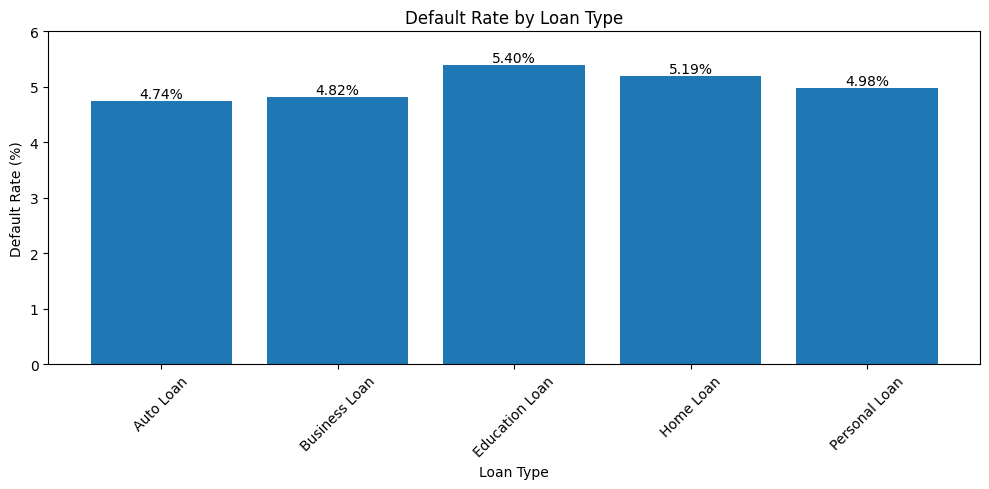

In [ ]:
plt.figure(figsize=(10, 5))

# Create bar chart
bars = plt.bar(
    loan_type_analysis.index,
    loan_type_analysis["default_rate"]
)

# Add chart title and axis labels
plt.title("Default Rate by Loan Type")
plt.xlabel("Loan Type")
plt.ylabel("Default Rate (%)")

# Add percentage labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

# Format chart
plt.xticks(rotation=45)
plt.ylim(0, 6)
plt.tight_layout()
plt.show()

In [ ]:
primary_keys = {
    "customers": "customer_id",
    "applications": "application_id",
    "loans": "loan_id",
    "transactions": "transaction_id",
    "repayments": "repayment_id"
}

for table_name, key_column in primary_keys.items():

    df = data[table_name]

    total_records = len(df)
    unique_ids = df[key_column].nunique()
    duplicate_ids = df[key_column].duplicated().sum()
    missing_ids = df[key_column].isnull().sum()

    print(f"\nTable: {table_name}")
    print(f"Total records: {total_records}")
    print(f"Unique IDs: {unique_ids}")
    print(f"Duplicate IDs: {duplicate_ids}")
    print(f"Missing IDs: {missing_ids}")


Table: customers
Total records: 87719
Unique IDs: 87719
Duplicate IDs: 0
Missing IDs: 0

Table: applications
Total records: 131579
Unique IDs: 131579
Duplicate IDs: 0
Missing IDs: 0

Table: loans
Total records: 65789
Unique IDs: 65789
Duplicate IDs: 0
Missing IDs: 0

Table: transactions
Total records: 438601
Unique IDs: 438601
Duplicate IDs: 0
Missing IDs: 0

Table: repayments
Total records: 526312
Unique IDs: 526312
Duplicate IDs: 0
Missing IDs: 0


In [ ]:
for table_name, df in data.items():

    print("\n" + "=" * 60)
    print(f"TABLE: {table_name.upper()}")
    print("=" * 60)

    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    print("\nColumn names and data types:")
    print(df.dtypes)

    print("\nMemory usage:")
    print(round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2), "MB")


TABLE: CUSTOMERS
Number of rows: 87719
Number of columns: 9

Column names and data types:
customer_id                          object
age                                   int64
city                                 object
employment_type                      object
annual_income_inr                     int64
existing_monthly_debt_inr             int64
customer_since               datetime64[ns]
kyc_status                           object
risk_segment                         object
dtype: object

Memory usage:
26.54 MB

TABLE: APPLICATIONS
Number of rows: 131579
Number of columns: 11

Column names and data types:
application_id                        object
customer_id                           object
application_date              datetime64[ns]
loan_type                             object
requested_amount_inr                   int64
annual_income_inr                      int64
credit_score                           int64
debt_to_income_ratio                 float64
employment_stabilit

In [ ]:
for table_name, df in data.items():

    print(f"\n{table_name.upper()}")

    for col in df.columns:
        if col != col.strip():
            print("Column with extra spaces:", repr(col))

    print("Total columns:", len(df.columns))


CUSTOMERS
Total columns: 9

APPLICATIONS
Total columns: 11

LOANS
Total columns: 12

TRANSACTIONS
Total columns: 13

REPAYMENTS
Total columns: 10


In [ ]:
# Export analysis outputs to a separate folder; do not overwrite source datasets.
export_path = project_root / "outputs" / "python_analysis"
export_path.mkdir(parents=True, exist_ok=True)

for table_name, df in data.items():
    file_path = export_path / f"{table_name}_analysis_output.csv"
    df.to_csv(file_path, index=False)
    print(f"{file_path.name} exported successfully")
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("-" * 40)

customers_cleaned.csv exported successfully
Rows: 87719
Columns: 9
----------------------------------------
applications_cleaned.csv exported successfully
Rows: 131579
Columns: 11
----------------------------------------
loans_cleaned.csv exported successfully
Rows: 65789
Columns: 12
----------------------------------------
transactions_cleaned.csv exported successfully
Rows: 438601
Columns: 13
----------------------------------------
repayments_cleaned.csv exported successfully
Rows: 526312
Columns: 10
----------------------------------------


In [ ]:
import os

for table_name in data.keys():

    file_name = f"{table_name}_cleaned.csv"
    file_path = os.path.join(export_path, file_name)

    if os.path.exists(file_path):
        file_size = os.path.getsize(file_path) / (1024 ** 2)

        print(f"{file_name}")
        print("File exists: Yes")
        print(f"File size: {file_size:.2f} MB")
        print("-" * 40)

    else:
        print(f"{file_name} NOT FOUND")

customers_cleaned.csv
File exists: Yes
File size: 6.03 MB
----------------------------------------
applications_cleaned.csv
File exists: Yes
File size: 13.73 MB
----------------------------------------
loans_cleaned.csv
File exists: Yes
File size: 5.99 MB
----------------------------------------
transactions_cleaned.csv
File exists: Yes
File size: 49.96 MB
----------------------------------------
repayments_cleaned.csv
File exists: Yes
File size: 47.26 MB
----------------------------------------
